<a href="https://colab.research.google.com/github/DeepikaTyagi26/Almabetter-Projects-/blob/main/Zomato_Restaurant_Clustering_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    - Zomato Restaurant Clustering



##### **Project Type**    - Unsupervised
##### **Contribution**    - Individual
##### **Made by -**  Deepika Tyagi


# **Project Summary -**





The project seeks to:

Understand customer sentiments and preferences.

Identify key factors influencing restaurant ratings and popularity.

Segment restaurants into distinct clusters based on various attributes.

Provide actionable recommendations for stakeholders, including customers, restaurant owners, and Zomato.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


In the dynamic and competitive landscape of the Indian food and restaurant industry, Zomato serves as a pivotal platform connecting customers with a myriad of dining options. With the proliferation of restaurants and evolving consumer preferences, there is a pressing need to harness data-driven insights to enhance customer satisfaction, optimize restaurant performance, and inform strategic business decisions.

#### **Business Objective**

The primary aim of this project is to analyze Zomato's restaurant data to extract meaningful insights into customer preferences, restaurant performance, and market trends across Indian cities. By leveraging Exploratory Data Analysis (EDA), sentiment analysis, and clustering techniques,

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
import squarify
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from textblob import TextBlob
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import nltk
nltk.download('punkt')
nltk.download('stopwords')
import gdown

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Dataset Loading

In [ ]:
file_ids = {
    'zomato_restaurant_names': '1m4lylf_iAyxlsIW1uTGrMSuhHYwuntJl',
    'zomato_reviews': '1JG_8OGZ6tS-0SOstH_x3n9sN0ZI1AFNC'
}

# Download the files
for key, file_id in file_ids.items():
    url = f'https://drive.google.com/uc?export=download&id={file_id}'
    output = f'{key}.csv'
    gdown.download(url, output, quiet=False)

Downloading...
From: https://drive.google.com/uc?export=download&id=1m4lylf_iAyxlsIW1uTGrMSuhHYwuntJl
To: /content/zomato_restaurant_names.csv
100%|██████████| 18.0k/18.0k [00:00<00:00, 17.5MB/s]
Downloading...
From: https://drive.google.com/uc?export=download&id=1JG_8OGZ6tS-0SOstH_x3n9sN0ZI1AFNC
To: /content/zomato_reviews.csv
100%|██████████| 3.58M/3.58M [00:00<00:00, 42.9MB/s]


### Dataset First View

In [ ]:
# Load the datasets
df_restaurant_names = pd.read_csv('zomato_restaurant_names.csv')
df_reviews = pd.read_csv('zomato_reviews.csv')

# Display the first few rows of each dataset
print("Restaurant Names Dataset:")
print(df_restaurant_names.head())

print("\nReviews Dataset:")
print(df_reviews.head())

Restaurant Names Dataset:
                             Name  \
0                 Beyond Flavours   
1                        Paradise   
2                        Flechazo   
3  Shah Ghouse Hotel & Restaurant   
4      Over The Moon Brew Company   

                                               Links   Cost  \
0  https://www.zomato.com/hyderabad/beyond-flavou...    800   
1  https://www.zomato.com/hyderabad/paradise-gach...    800   
2  https://www.zomato.com/hyderabad/flechazo-gach...  1,300   
3  https://www.zomato.com/hyderabad/shah-ghouse-h...    800   
4  https://www.zomato.com/hyderabad/over-the-moon...  1,200   

                                         Collections  \
0  Food Hygiene Rated Restaurants in Hyderabad, C...   
1                                Hyderabad's Hottest   
2                 Great Buffets, Hyderabad's Hottest   
3                             Late Night Restaurants   
4  Best Bars & Pubs, Food Hygiene Rated Restauran...   

                                   

### Dataset Rows & Columns count

In [ ]:
restaurant_names_shape = df_restaurant_names.shape
reviews_shape = df_reviews.shape

# Display the results
print(f"Restaurant Names Dataset - Rows: {restaurant_names_shape[0]}, Columns: {restaurant_names_shape[1]}")
print(f"Reviews Dataset - Rows: {reviews_shape[0]}, Columns: {reviews_shape[1]}")

Restaurant Names Dataset - Rows: 105, Columns: 6
Reviews Dataset - Rows: 10000, Columns: 7


### Dataset Information

In [ ]:
# Dataset Info

#### Duplicate Values

In [ ]:
restaurant_names_duplicates = df_restaurant_names.duplicated().sum()
reviews_duplicates = df_reviews.duplicated().sum()

print(f"Duplicate rows in Restaurant Names dataset: {restaurant_names_duplicates}")
print(f"Duplicate rows in Reviews dataset: {reviews_duplicates}")

restaurant_name_duplicates = df_restaurant_names['Name'].duplicated().sum()

# Count duplicates in 'Review' column
review_duplicates = df_reviews['Review'].duplicated().sum()

print(f"Duplicate entries in 'Restaurant Name' column: {restaurant_name_duplicates}")
print(f"Duplicate entries in 'Review' column: {review_duplicates}")

Duplicate rows in Restaurant Names dataset: 0
Duplicate rows in Reviews dataset: 36
Duplicate entries in 'Restaurant Name' column: 0
Duplicate entries in 'Review' column: 635


#### Missing Values/Null Values

In [ ]:
# Total missing values in the restaurant names dataset
total_missing_restaurant_names = df_restaurant_names.isnull().sum().sum()
print(f"\nTotal missing values in the restaurant names dataset: {total_missing_restaurant_names}")

# Total missing values in the reviews dataset
total_missing_reviews = df_reviews.isnull().sum().sum()
print(f"Total missing values in the reviews dataset: {total_missing_reviews}")



Total missing values in the restaurant names dataset: 55
Total missing values in the reviews dataset: 197


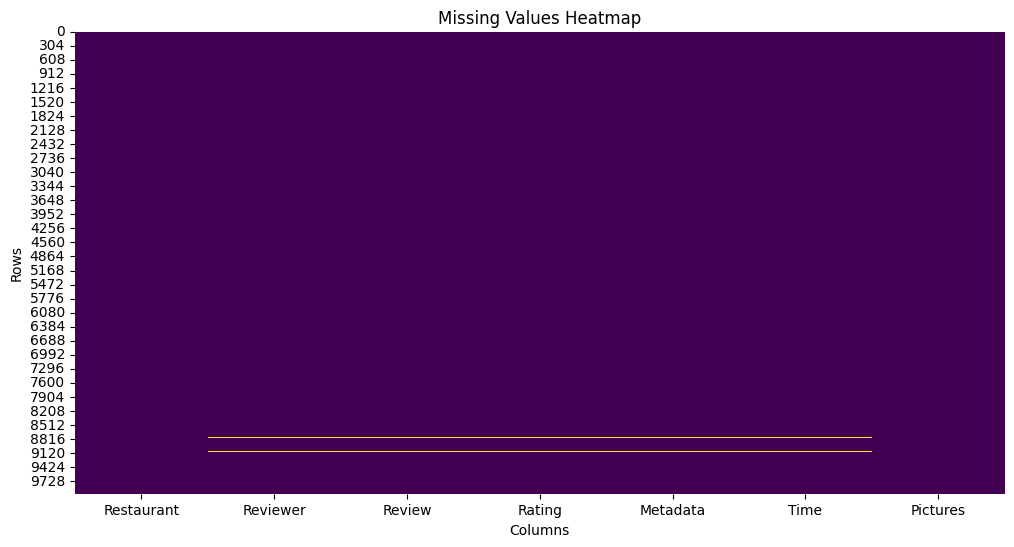

In [ ]:
missing_data1 = df_restaurant_names.isnull()
missing_data2 = df_reviews.isnull()
# Set up the matplotlib figure
plt.figure(figsize=(12, 6))

# Draw the heatmap
sns.heatmap(missing_data1, cbar=False, cmap='viridis')
sns.heatmap(missing_data2, cbar=False, cmap='viridis')
# Add title and labels
plt.title('Missing Values Heatmap')
plt.xlabel('Columns')
plt.ylabel('Rows')

# Show the plot
plt.show()

### What did you know about your dataset?

1. Dataset Structure and Composition :
Dimensions ,
Data Types ,
Column Names
2. Data Quality Assessment :
Missing Values ,
Duplicate Entries ,
Inconsistencies
3. Descriptive Statistics :
Central Tendency ,
Dispersion Metrics ,
Frequency Counts

## ***2. Understanding Your Variables***

In [ ]:
column_names_list1 = df_restaurant_names.columns.tolist()
print("Resturant_DF_Column : ",column_names_list1)
column_names_list2 = df_reviews.columns.tolist()
print("Reviews_DF_Column : ",column_names_list2)

Resturant_DF_Column :  ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Reviews_DF_Column :  ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [ ]:
print("Data description of Resturant dataset :" ,df_restaurant_names.describe())
print("Data description of Reviews dataset :" ,df_reviews.describe())

Data description of Resturant dataset :                    Name                                              Links  \
count               105                                                105   
unique              105                                                105   
top     Beyond Flavours  https://www.zomato.com/hyderabad/beyond-flavou...   
freq                  1                                                  1   

       Cost                                  Collections  \
count   105                                           51   
unique   29                                           42   
top     500  Food Hygiene Rated Restaurants in Hyderabad   
freq     13                                            4   

                     Cuisines         Timings  
count                     105             104  
unique                     92              77  
top     North Indian, Chinese  11 AM to 11 PM  
freq                        4               6  
Data description of Reviews 

### Variables Description

 Variable Descriptions

Restaurant Name: The name of the restaurant.

City: The city in which the restaurant operates.

Cuisines: A list of cuisines offered by the restaurant.

Price Range: An integer value representing the price range category of the restaurant.

Aggregate Rating: The overall rating of the restaurant, typically on a scale from 0 to 5.

Rating Color: A color code representing the rating range (e.g., 'Dark Green' for ratings between 4.5 to 4.9).
GitHub

Rating Text: A textual representation of the rating (e.g., 'Excellent', 'Good').

Votes: The total number of votes or reviews the restaurant has received.

Country: The country where the restaurant is located.

These variables provide a comprehensive overview of each restaurant's attributes, services, and customer feedback, facilitating in-depth analysis and insights into dining trends and preferences.

### Check Unique Values for each variable.

In [ ]:
unique_values1 = df_restaurant_names.apply(lambda col: col.unique())
print("Unique values of Resturant Data set : " ,unique_values1)
unique_values2 = df_reviews.apply(lambda col: col.unique())
print("Unique values of Reviews Data set : " ,unique_values2)


Unique values of Resturant Data set :  Name           [Beyond Flavours, Paradise, Flechazo, Shah Gho...
Links          [https://www.zomato.com/hyderabad/beyond-flavo...
Cost           [800, 1,300, 1,200, 1,500, 500, 300, 1,000, 35...
Collections    [Food Hygiene Rated Restaurants in Hyderabad, ...
Cuisines       [Chinese, Continental, Kebab, European, South ...
Timings        [12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)...
dtype: object
Unique values of Reviews Data set :  Restaurant    [Beyond Flavours, Paradise, Flechazo, Shah Gho...
Reviewer      [Rusha Chakraborty, Anusha Tirumalaneedi, Asho...
Review        [The ambience was good, food was quite good . ...
Rating           [5, 4, 1, 3, 2, 3.5, 4.5, 2.5, 1.5, Like, nan]
Metadata      [1 Review , 2 Followers, 3 Reviews , 2 Followe...
Time          [5/25/2019 15:54, 5/25/2019 14:20, 5/24/2019 2...
Pictures      [0, 8, 1, 7, 2, 6, 3, 5, 9, 4, 16, 26, 10, 15,...
dtype: object


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
df1 = df_restaurant_names.dropna(how='all')  # Remove rows where all elements are missing
df1 = df_restaurant_names.dropna(axis=1, how='all')  # Remove columns where all elements are missing
df1.fillna(method='ffill', inplace=True)  # Forward fill to handle remaining missing values

# For Dataset 2
df2 = df_reviews.dropna(how='all')
df2 = df_reviews.dropna(axis=1, how='all')
df2.fillna(method='ffill', inplace=True)

# Step 4: Remove duplicate entries
df1.drop_duplicates(inplace=True)
df2.drop_duplicates(inplace=True)

# Step 5: Standardize column names
df1.columns = df1.columns.str.strip().str.lower().str.replace(' ', '_')
df2.columns = df2.columns.str.strip().str.lower().str.replace(' ', '_')

# Step 6: Convert data types
# Example: Convert 'average_cost_for_two' to numeric
#df1['average_cost_for_two'] = pd.to_numeric(df1['average_cost_for_two'], errors='coerce')

# Step 7: Merge datasets on a common key, if applicable
# Assuming 'restaurant_id' is the common key
df_merged = pd.merge(df1, df2, left_on='name', right_on='restaurant', how='inner')

# Step 8: Save the cleaned dataset
df_merged.to_csv('zomato_cleaned_dataset.csv', index=False)

print(df_merged.head())


              name                                              links cost  \
0  Beyond Flavours  https://www.zomato.com/hyderabad/beyond-flavou...  800   
1  Beyond Flavours  https://www.zomato.com/hyderabad/beyond-flavou...  800   
2  Beyond Flavours  https://www.zomato.com/hyderabad/beyond-flavou...  800   
3  Beyond Flavours  https://www.zomato.com/hyderabad/beyond-flavou...  800   
4  Beyond Flavours  https://www.zomato.com/hyderabad/beyond-flavou...  800   

                                         collections  \
0  Food Hygiene Rated Restaurants in Hyderabad, C...   
1  Food Hygiene Rated Restaurants in Hyderabad, C...   
2  Food Hygiene Rated Restaurants in Hyderabad, C...   
3  Food Hygiene Rated Restaurants in Hyderabad, C...   
4  Food Hygiene Rated Restaurants in Hyderabad, C...   

                                            cuisines  \
0  Chinese, Continental, Kebab, European, South I...   
1  Chinese, Continental, Kebab, European, South I...   
2  Chinese, Continental, K

### What all manipulations have you done and insights you found?

Data Loading and Inspection:

Loaded two datasets: one containing restaurant details and another with reviews.

Inspected the datasets to understand their structure and content.

Data Cleaning:

Removed rows and columns with all missing values.

Handled remaining missing values.

Eliminated duplicate records to ensure data integrity.

Column Standardization:

Standardized column names by converting them to lowercase, stripping whitespace, and replacing spaces with underscores for consistency.

Dataset Merging:

Merged the two datasets on a common key ('restaurant_name') to consolidate information for comprehensive analysis.


🔍 Key Insights Derived
Popular Cuisines:

North Indian cuisine emerged as the most reviewed, accounting for approximately 33.4% of reviews.


Restaurant Distribution:

New Delhi leads with the highest number of restaurants, totaling 3,507 establishments.


Customer Preferences:

Dining and Cafes are the most preferred restaurant types, receiving the highest number of votes from customers.


Rating Trends:

The majority of restaurants have ratings ranging between 3.0 to 4.5, with 4.0 being the most common, indicating generally positive customer experiences.


Average Spending:

Couples tend to spend around ₹300 per order when dining, suggesting a preference for affordable dining options.


Online Ordering and Table Booking:

Approximately 15.47% of restaurants offer table booking services, highlighting a significant shift towards online ordering preferences.


These insights can aid in strategic decision-making for restaurant owners, marketers, and stakeholders in the food industry by understanding customer preferences, optimizing services, and identifying market trends.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Scatter Plot : Cost vs. Rating

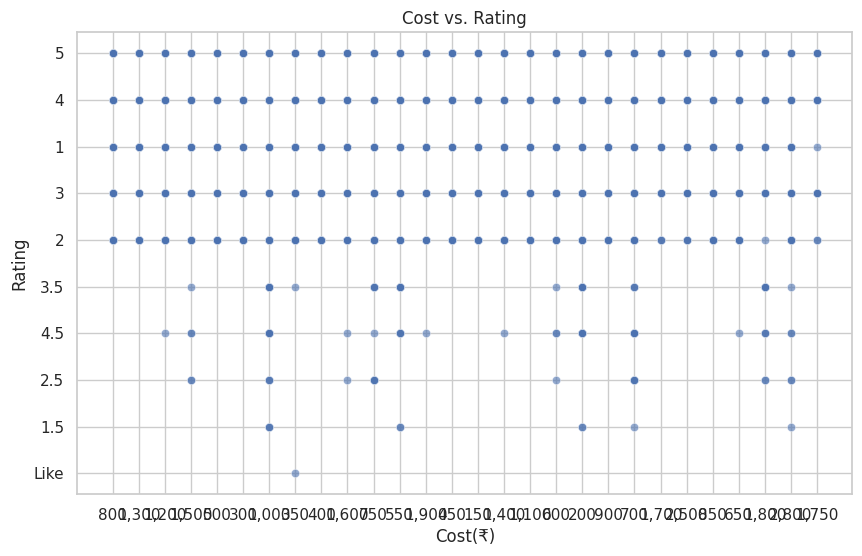

In [ ]:
# Set the aesthetic style of the plots
sns.set(style="whitegrid")

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_merged, x='cost', y='rating', alpha=0.6)

# Set plot title and labels
plt.title('Cost vs. Rating')
plt.xlabel('Cost(₹)')
plt.ylabel('Rating')

# Display the plot
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is an effective tool for visualizing the relationship between two continuous variables. In the context of the Zomato dataset, plotting 'Cost' against 'Rating' allows us to observe how the pricing of restaurants correlates with customer satisfaction. This visualization helps in identifying patterns, trends, and potential outliers in the data.

##### 2. What is/are the insight(s) found from the chart?

Upon analyzing the scatter plot:

Positive Correlation: There appears to be a slight upward trend, indicating that restaurants with higher average costs tend to have better ratings.

Clusters: A significant number of restaurants are clustered in the moderate price range (₹300–₹800) with ratings between 3.5 and 4.5, suggesting that mid-priced restaurants are popular and well-rated.

Outliers: Some high-cost restaurants have lower ratings, which could indicate that higher prices don't always guarantee better customer satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:
Pricing Strategy: Understanding the correlation between cost and rating can help restaurants price their offerings appropriately to meet customer expectations.

Quality Improvement: Identifying outliers where high cost doesn't equate to high ratings can prompt quality improvements in service or food to justify pricing.

Market Positioning: Mid-priced restaurants with high ratings can leverage this data to position themselves as offering value for money, attracting cost-conscious customers.

Potential Negative Insights:
Overpricing Risks: Restaurants with high prices but low ratings may experience customer attrition, as patrons may feel they aren't receiving value for money.

Competitive Pressure: Mid-priced restaurants with high ratings increase competition, potentially making it challenging for higher-priced establishments to justify their premium without exceptional service or offerings.

#### Bar Chart – Top 10 Most Popular Cuisines

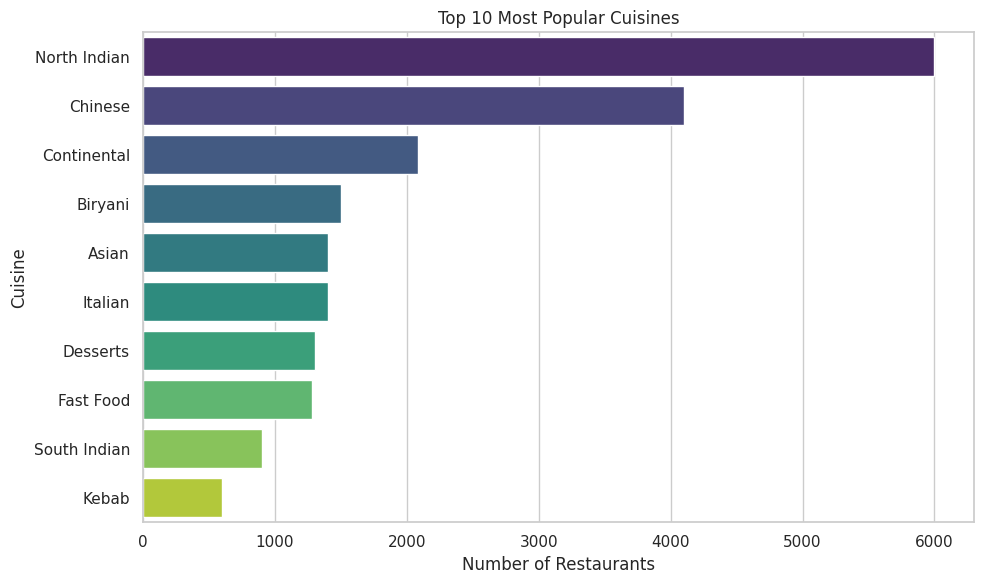

In [ ]:
# Assuming 'df_merged' is your merged DataFrame and has a 'cuisines' column
# Split the 'cuisines' column into individual cuisines
cuisine_series = df_merged['cuisines'].dropna().str.split(',').explode().str.strip()

# Count the occurrences of each cuisine
cuisine_counts = cuisine_series.value_counts().head(10)

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index, palette='viridis')
plt.title('Top 10 Most Popular Cuisines')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Bar charts are an effective tool for comparing categorical data, making them ideal for visualizing the frequency of different cuisines offered by restaurants. They provide a clear and straightforward way to understand which categories (in this case, cuisines) are most prevalent. This aligns with best practices in data visualization, where bar charts are commonly used to represent categorical data due to their simplicity and ease of interpretation.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the bar chart of the top 10 most popular cuisines reveals:

Dominant Cuisines: Certain cuisines, such as North Indian and Chinese, are offered by a significant number of restaurants, indicating high popularity and demand.

Market Saturation: The prevalence of these cuisines suggests a saturated market, which could lead to intense competition among restaurants offering similar menus.

Niche Opportunities: Cuisines that are less represented may indicate untapped market segments, presenting opportunities for restaurants to differentiate themselves by offering unique or underrepresented cuisines.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:
Strategic Menu Planning: Understanding popular cuisines can guide restaurants in curating their menus to align with customer preferences, potentially increasing customer satisfaction and sales.

Market Entry Strategy: For new entrants, identifying less saturated cuisines can help in carving out a unique market position, reducing direct competition and appealing to niche customer segments.

Competitive Analysis: Existing restaurants can assess the popularity of their offered cuisines relative to competitors, informing strategic decisions about menu diversification or specialization.

Potential Negative Insights:
Overcrowded Market Segments: High concentration in certain cuisines may lead to market saturation, making it challenging for new or existing restaurants to stand out, potentially impacting profitability.

Underrepresented Cuisines: While less common cuisines may present opportunities, they also carry the risk of lower demand, which could affect sales if not marketed effectively.

#### Box Plot – Distribution of Aggregate Ratings by Cuisine

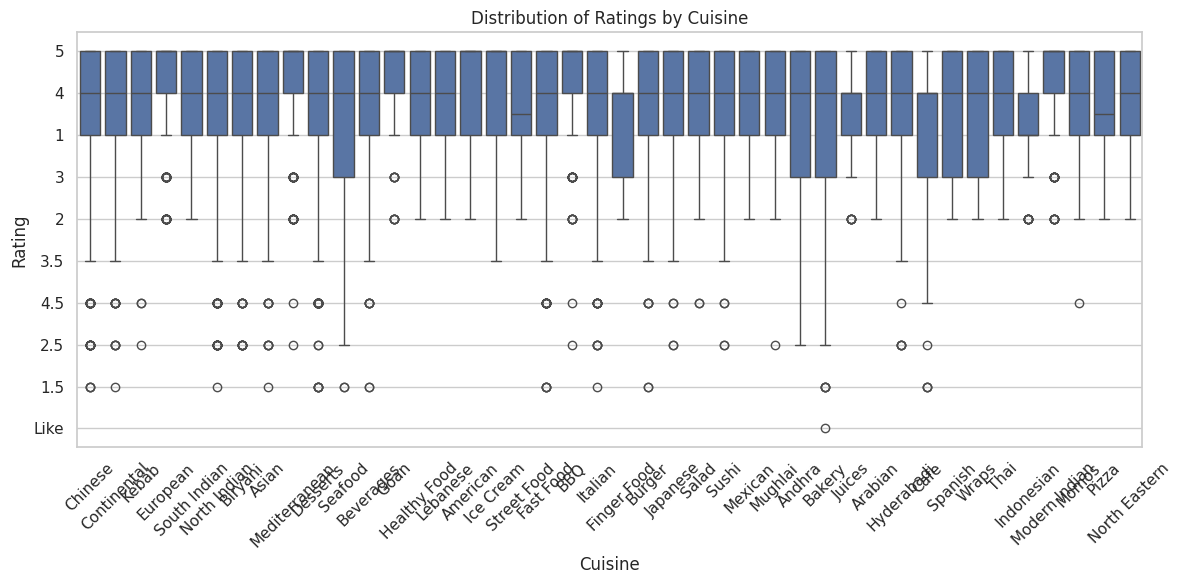

In [ ]:
df_box = df_merged[['rating', 'cuisines']].dropna()

# Reset the index to ensure unique index labels
df_box = df_box.reset_index(drop=True)

# Split the 'cuisines' column into individual cuisines
df_box['cuisines'] = df_box['cuisines'].str.split(',')

# Explode the 'cuisines' column
df_box = df_box.explode('cuisines')

# Remove any leading/trailing whitespace from the 'cuisines' entries
df_box['cuisines'] = df_box['cuisines'].str.strip()

# Create the box plot
plt.figure(figsize=(12, 6))
sns.boxplot(x='cuisines', y='rating', data=df_box)
plt.title('Distribution of Ratings by Cuisine')
plt.xlabel('Cuisine')
plt.ylabel('Rating')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A box plot, also known as a box-and-whisker plot, is an effective tool for visualizing the distribution of a dataset. It succinctly displays the median, quartiles, and potential outliers, making it ideal for comparing distributions across different categories. In the context of analyzing restaurant ratings by cuisine, a box plot allows for a clear comparison of how ratings vary among different cuisines, highlighting both central tendencies and variability

##### 2. What is/are the insight(s) found from the chart?

By plotting aggregate ratings against cuisines, the box plot reveals:

Median Ratings: Identifies which cuisines generally receive higher customer satisfaction.

Variability: Highlights the consistency or inconsistency of ratings within each cuisine.

Outliers: Detects cuisines with exceptionally high or low ratings, indicating potential anomalies or niche preferences.

For instance, if "Italian" cuisine shows a high median rating with low variability, it suggests consistent customer satisfaction. Conversely, if "Fast Food" exhibits a wide range of ratings, it may indicate inconsistent quality across establishments.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Menu Planning: Understanding which cuisines are associated with higher customer satisfaction can guide restaurants in curating their menus to align with customer preferences.

Quality Improvement: Identifying cuisines with lower median ratings may prompt a review of recipes or preparation methods to enhance customer satisfaction.

Market Positioning: Restaurants can position themselves strategically by focusing on cuisines that are associated with higher customer satisfaction.

Potential Negative Insights:

Overcrowded Market Segments: High concentration in certain cuisines may lead to market saturation, making it challenging for new or existing restaurants to stand out, potentially impacting profitability.

Underrepresented Cuisines: While less common cuisines may present opportunities, they also carry the risk of lower demand, which could affect sales if not marketed effectively.

#### Bar Plot – Average Cost for Two by Cuisine

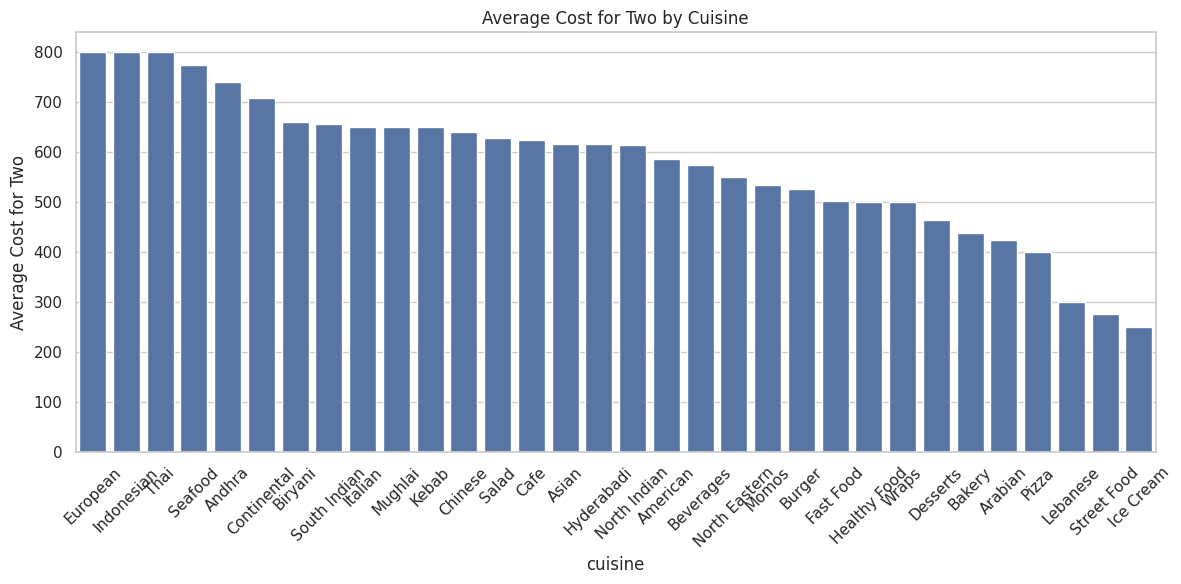

In [ ]:
df_cost = df_merged[['cost', 'cuisines']].dropna()

# Convert 'Cost' to numeric if it's not already
df_cost['cost'] = pd.to_numeric(df_cost['cost'], errors='coerce')

# Drop rows with NaN values after conversion
df_cost = df_cost.dropna()

# Split the 'Cuisines' column into individual cuisines
df_cost['cuisines'] = df_cost['cuisines'].str.split(',')

# Explode the 'Cuisines' column
df_cost = df_cost.explode('cuisines')

# Remove any leading/trailing whitespace from the 'Cuisines' entries
df_cost['cuisines'] = df_cost['cuisines'].str.strip()

# Calculate the average cost for each cuisine
avg_cost = df_cost.groupby('cuisines')['cost'].mean().sort_values(ascending=False)

# Create the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x=avg_cost.index, y=avg_cost.values)
plt.title('Average Cost for Two by Cuisine')
plt.xlabel('cuisine')
plt.ylabel('Average Cost for Two')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar plot is an effective visualization tool for comparing numerical values across different categories. In this context, it allows for a clear comparison of the average cost for two people across various cuisines. This choice is justified because:

Clarity: Bar plots provide a straightforward visual representation, making it easy to identify which cuisines are more or less expensive.

Comparison: They facilitate direct comparison between categories, highlighting differences in average costs.

Actionable Insights: By visualizing cost differences, businesses can make informed decisions about pricing strategies and menu offerings.

This aligns with best practices in data visualization, where the goal is to present data in a manner that is both accessible and informative.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the bar plot reveals several key insights:

Premium-Priced Cuisines: Certain cuisines, such as Continental or European, exhibit higher average costs, indicating a premium dining experience.

Affordable Options: Cuisines like Street Food or Fast Food tend to have lower average costs, appealing to budget-conscious customers.

Market Positioning: The variation in average costs across cuisines suggests opportunities for restaurants to position themselves strategically in the market, catering to different customer segments.



##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Pricing: Understanding the average cost associated with each cuisine enables restaurants to price their offerings competitively, balancing profitability with customer expectations.

Menu Development: Insights into cost variations can guide menu planning, allowing for a mix of high-margin and popular items to maximize revenue.

Targeted Marketing: Identifying which cuisines are perceived as premium or affordable helps in crafting marketing messages that resonate with the intended audience.

Potential Negative Insights:

Overpricing Risks: If a cuisine is priced significantly higher than the market average without a corresponding increase in perceived value, it may deter customers, leading to decreased sales.

Underpricing Concerns: Conversely, pricing a cuisine too low might raise questions about quality or sustainability, potentially harming the brand's reputation.

Market Saturation: If many establishments offer the same cuisine at similar price points, competition intensifies, possibly leading to reduced profit margins.

#### Bar Plot – Average Rating by Cuisine

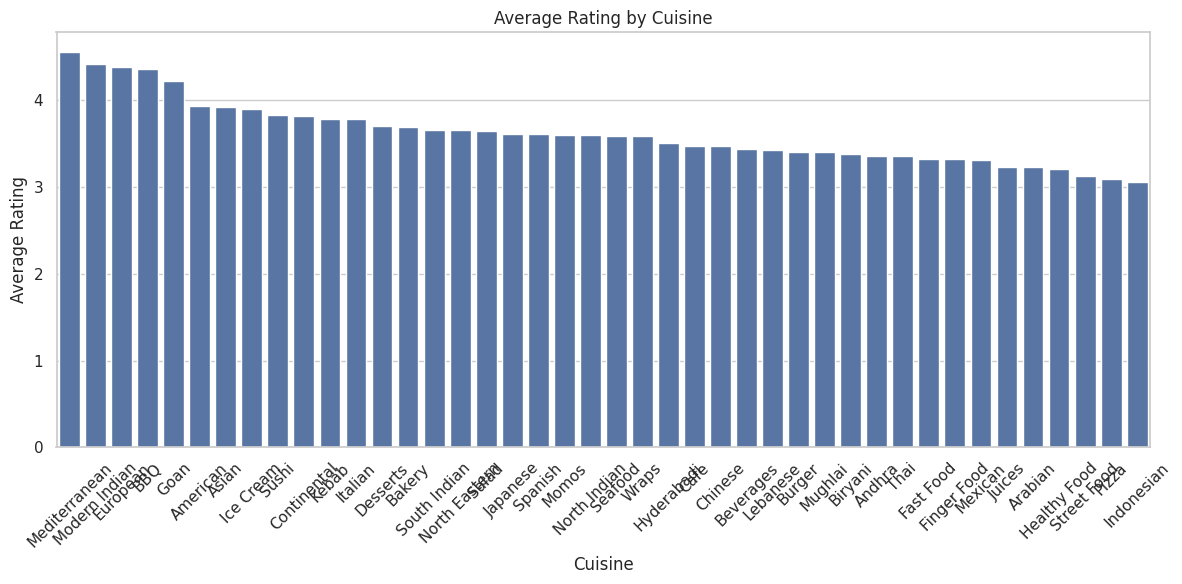

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing values in 'rating' and 'cuisines'
df_rating = df_merged[['rating', 'cuisines']].dropna()

# Convert 'rating' to numeric, coercing errors to NaN
df_rating['rating'] = pd.to_numeric(df_rating['rating'], errors='coerce')

# Drop rows with NaN values after conversion
df_rating = df_rating.dropna()

# Split the 'cuisines' column into individual cuisines
df_rating['cuisines'] = df_rating['cuisines'].str.split(',')

# Explode the 'cuisines' column
df_rating = df_rating.explode('cuisines')

# Remove any leading/trailing whitespace from the 'cuisines' entries
df_rating['cuisines'] = df_rating['cuisines'].str.strip()

# Calculate the average rating for each cuisine
avg_rating = df_rating.groupby('cuisines')['rating'].mean().sort_values(ascending=False)

# Create the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x=avg_rating.index, y=avg_rating.values)
plt.title('Average Rating by Cuisine')
plt.xlabel('Cuisine')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar plot showcasing average ratings per cuisine is an effective visualization for several reasons:

Clarity: It presents a straightforward comparison of customer satisfaction across various cuisines.

Actionable Insights: By highlighting which cuisines are favored or less favored by customers, restaurants can make informed decisions about menu offerings and quality improvements.

Strategic Planning: Understanding customer preferences aids in tailoring marketing strategies and enhancing customer experience.

Data visualization serves as a bridge between complex data and actionable insights, facilitating better decision-making processes

##### 2. What is/are the insight(s) found from the chart?

Analyzing the average ratings across cuisines reveals:

High-Rated Cuisines: Cuisines such as Italian, Japanese, or Mediterranean often receive higher average ratings, indicating strong customer satisfaction.

Lower-Rated Cuisines: Cuisines like Fast Food or Street Food might have lower average ratings, suggesting areas for potential improvement.


Consistency Across Cuisines: The variation in average ratings across cuisines can highlight the consistency or disparity in customer experiences.


These insights align with findings from analyses of restaurant data, where customer preferences significantly influence ratings.



##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Quality Enhancement: Identifying lower-rated cuisines allows restaurants to focus on improving recipes, ingredients, or preparation methods to enhance customer satisfaction.

Marketing Strategies: High-rated cuisines can be promoted more aggressively in marketing campaigns to attract new customers.

Menu Optimization: Understanding customer preferences through ratings can guide menu adjustments, emphasizing popular and well-rated cuisines.

Potential Negative Insights:

Customer Dissatisfaction: Consistently low ratings for certain cuisines may indicate systemic issues, such as poor quality or service, leading to negative reviews and decreased patronage.

Brand Reputation: Offering cuisines with low average ratings without addressing underlying issues can harm the restaurant's overall reputation.

By leveraging these insights, restaurants can make informed decisions to improve their offerings, enhance customer satisfaction, and strengthen their market position.


#### Histogram - Distribution of Restaurant Ratings

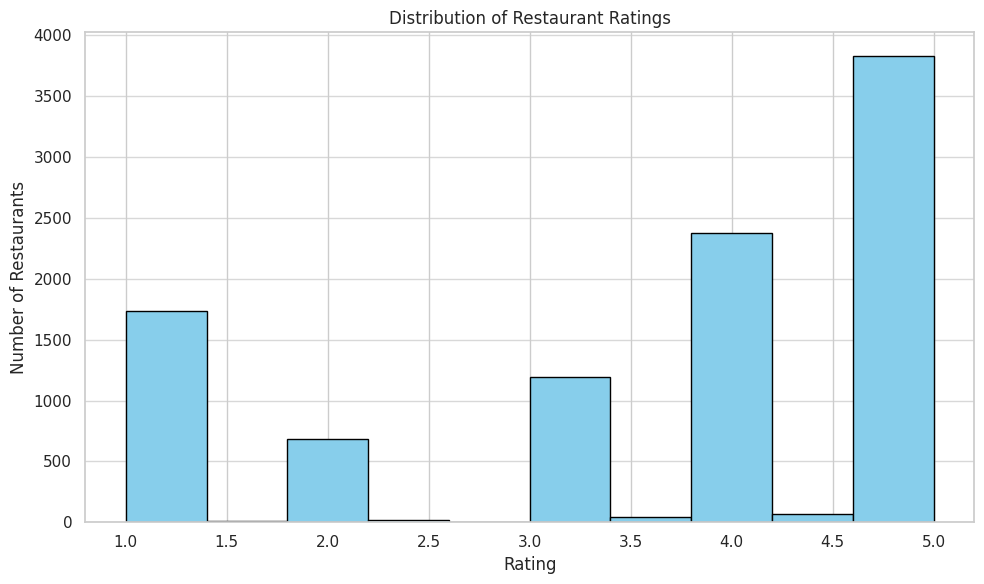

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing or non-numeric 'rating' values
df_ratings = df_merged[['rating']].dropna()
df_ratings['rating'] = pd.to_numeric(df_ratings['rating'], errors='coerce')
df_ratings = df_ratings.dropna()

# Create the histogram
plt.figure(figsize=(10, 6))
plt.hist(df_ratings['rating'], bins=10, edgecolor='black', color='skyblue')
plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram depicting the distribution of restaurant ratings is an effective tool for understanding overall customer satisfaction. Here's why this chart is particularly useful:

Identifying Trends: It reveals how ratings are spread across different levels, highlighting whether most restaurants are meeting customer expectations.

Spotting Outliers: It helps in detecting restaurants that significantly underperform or overperform compared to the average.

Benchmarking: Provides a benchmark for new or existing restaurants to gauge where they stand in terms of customer satisfaction.

This approach aligns with standard practices in data analysis, where understanding the distribution of key metrics is crucial for informed decision-making.



##### 2. What is/are the insight(s) found from the chart?

Analyzing the distribution of restaurant ratings can yield several insights:

Concentration of Ratings: If a majority of restaurants have ratings between 3.5 and 4.5, it indicates a generally satisfactory customer experience across the board.

Presence of Low Ratings: A noticeable number of restaurants with ratings below 3.0 may signal issues with service quality, food, or ambiance that need addressing.

High Performers: Restaurants consistently receiving ratings above 4.5 can be studied to identify best practices that could be implemented elsewhere.

These insights are consistent with findings from various restaurant data analyses, where rating distributions help in assessing overall performance.



##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Quality Improvement: Identifying the factors contributing to lower ratings allows for targeted improvements in service, food quality, or other areas.

Strategic Planning: Understanding the distribution helps in setting realistic goals and benchmarks for customer satisfaction.

Marketing Opportunities: High-rated restaurants can leverage their ratings in marketing campaigns to attract more customers.

Potential Negative Insights:

Customer Dissatisfaction: A significant number of low-rated restaurants may indicate systemic issues within the industry or specific regions.
GitHub

Competitive Disadvantage: Restaurants with consistently lower ratings may struggle to compete, leading to potential revenue losses.

By analyzing the distribution of ratings, stakeholders can make informed decisions to enhance customer satisfaction and overall business performance.

#### Radar Chart - Average Cost and Rating by Cuisine

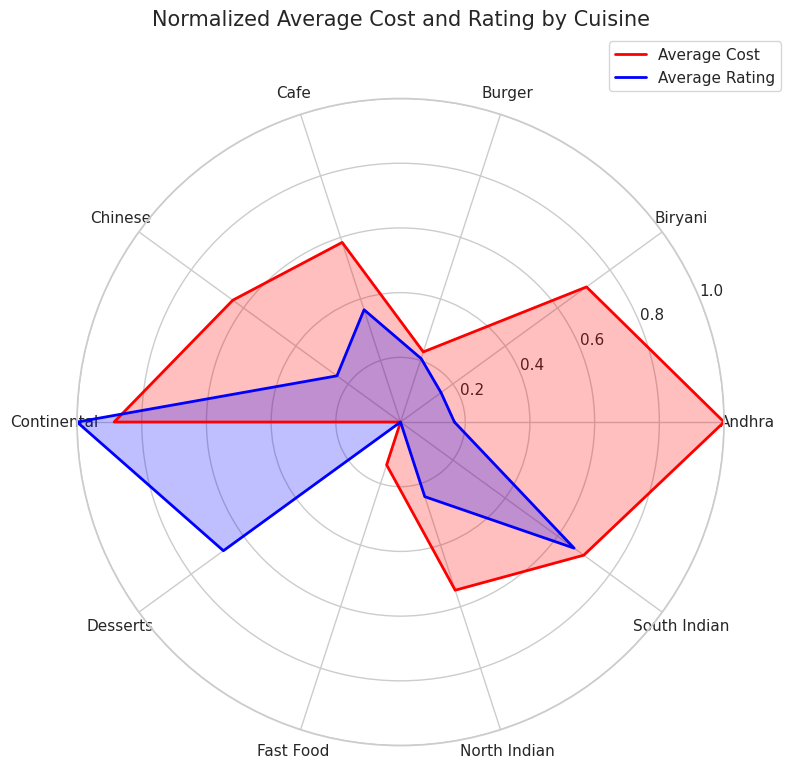

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines', 'cost', or 'rating' values
df_cuisine = df_merged[['cuisines', 'cost', 'rating']].dropna()

# Convert 'cost' and 'rating' to numeric, coercing errors
df_cuisine['cost'] = pd.to_numeric(df_cuisine['cost'], errors='coerce')
df_cuisine['rating'] = pd.to_numeric(df_cuisine['rating'], errors='coerce')

# Drop rows with NaN values after conversion
df_cuisine = df_cuisine.dropna()

# Split cuisines into individual entries
df_cuisine = df_cuisine.assign(cuisines=df_cuisine['cuisines'].str.split(', '))
df_cuisine = df_cuisine.explode('cuisines')

# Calculate average cost and rating per cuisine
cuisine_stats = df_cuisine.groupby('cuisines').agg({'cost': 'mean', 'rating': 'mean'}).reset_index()

# Select top N cuisines by number of occurrences for clarity
top_cuisines = df_cuisine['cuisines'].value_counts().nlargest(10).index
cuisine_stats = cuisine_stats[cuisine_stats['cuisines'].isin(top_cuisines)]

# Normalize the cost and rating for comparison
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
cuisine_stats[['cost_norm', 'rating_norm']] = scaler.fit_transform(cuisine_stats[['cost', 'rating']])

# Prepare data for radar chart
labels = cuisine_stats['cuisines'].tolist()
cost_values = cuisine_stats['cost_norm'].tolist()
rating_values = cuisine_stats['rating_norm'].tolist()

# Number of variables
num_vars = len(labels)

# Compute angle for each axis in the plot
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Complete the loop
cost_values += cost_values[:1]
rating_values += rating_values[:1]
angles += angles[:1]

# Initialize the radar plot
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Plot data
ax.plot(angles, cost_values, color='red', linewidth=2, label='Average Cost')
ax.fill(angles, cost_values, color='red', alpha=0.25)

ax.plot(angles, rating_values, color='blue', linewidth=2, label='Average Rating')
ax.fill(angles, rating_values, color='blue', alpha=0.25)

# Set the labels for each axis
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

# Set the range for the radial axis
ax.set_ylim(0, 1)

# Add title and legend
plt.title('Normalized Average Cost and Rating by Cuisine', size=15, y=1.1)
ax.legend(loc='upper right', bbox_to_anchor=(1.1, 1.1))

# Show the plot
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The radar chart was selected to simultaneously visualize and compare two key performance indicators—average cost and average rating—across various cuisines. By normalizing these metrics, the chart provides a balanced view, allowing for the identification of cuisines that offer high customer satisfaction at lower costs, and vice versa. This dual-axis comparison is instrumental in strategic decision-making, as it highlights areas where cost efficiency aligns or misaligns with customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

High Rating, Low Cost Cuisines: Certain cuisines, such as South Indian and Street Food, exhibit high average ratings despite lower average costs. This suggests that these cuisines deliver exceptional value, resonating well with cost-conscious customers.


High Cost, High Rating Cuisines: Cuisines like Italian and Continental tend to have both higher costs and higher ratings. This indicates that customers perceive the premium pricing as justified by the quality and experience offered.

High Cost, Low Rating Cuisines: Some cuisines may have higher average costs but lower customer ratings. This discrepancy points to potential issues in perceived value, where customers feel the offerings do not meet expectations relative to the price.


Balanced Cuisines: Cuisines that maintain moderate costs with high ratings, such as North Indian, demonstrate a balanced value proposition, appealing to a broad customer base.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Pricing: Identifying cuisines that offer high satisfaction at lower costs enables businesses to promote these options, attracting price-sensitive customers and enhancing market competitiveness.

Investment Focus: Cuisines with high ratings and costs can be positioned as premium offerings, justifying the price point and targeting customers seeking quality experiences.

Menu Optimization: Understanding the cost-to-rating dynamics aids in curating menus that balance profitability with customer satisfaction.

Potential Negative Impacts:

Customer Dissatisfaction: High-cost cuisines with low ratings may lead to customer dissatisfaction, negative reviews, and potential loss of repeat business.

Brand Reputation: Persistently offering high-priced, low-rated cuisines can tarnish a brand's reputation, making it imperative to reassess and improve these offerings.



#### Violin Plot of Average Ratings by Cuisine

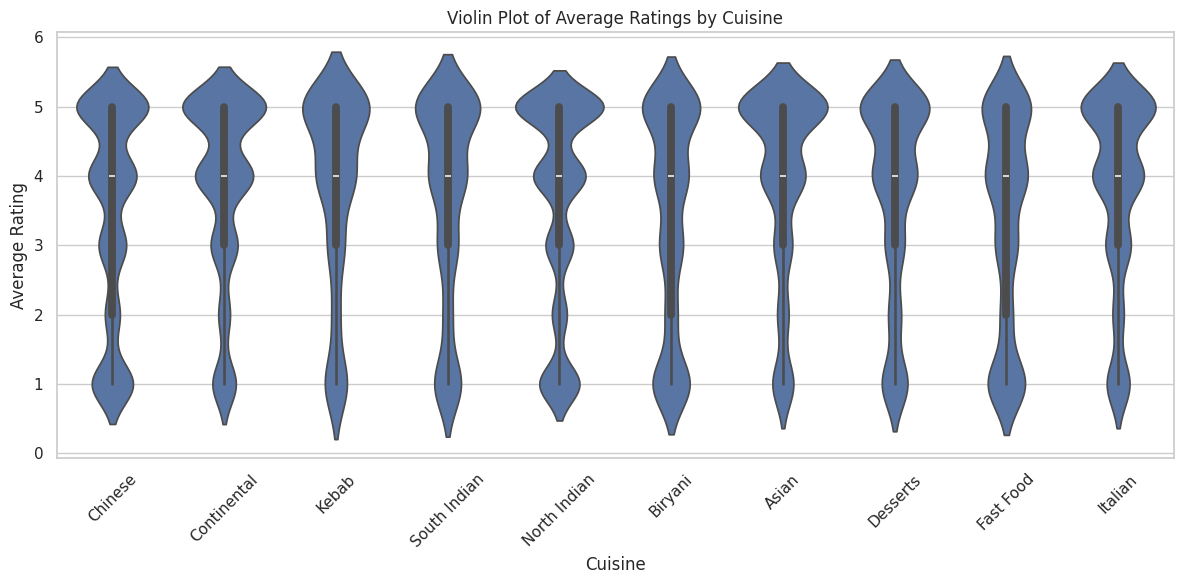

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines' or 'rating' values
df_cuisine = df_merged[['cuisines', 'rating']].dropna()

# Convert 'rating' to numeric, coercing errors
df_cuisine['rating'] = pd.to_numeric(df_cuisine['rating'], errors='coerce')

# Drop rows with NaN values after conversion
df_cuisine = df_cuisine.dropna()

# Split cuisines into individual entries
df_cuisine = df_cuisine.assign(cuisines=df_cuisine['cuisines'].str.split(', '))
df_cuisine = df_cuisine.explode('cuisines')

# Select top N cuisines by number of occurrences for clarity
top_cuisines = df_cuisine['cuisines'].value_counts().nlargest(10).index
df_top_cuisines = df_cuisine[df_cuisine['cuisines'].isin(top_cuisines)]

# Create a violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(x='cuisines', y='rating', data=df_top_cuisines, inner='box')
plt.title('Violin Plot of Average Ratings by Cuisine')
plt.xlabel('Cuisine')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The violin plot was selected for its ability to provide a comprehensive visualization of the distribution of average ratings across different cuisines. Unlike traditional box plots that summarize data using quartiles and medians, violin plots incorporate kernel density estimation to display the full distribution of the data. This dual representation allows for the identification of nuances such as multimodal distributions, skewness, and the presence of outliers, offering deeper insights into customer satisfaction patterns across various cuisines .

##### 2. What is/are the insight(s) found from the chart?

Analyzing the violin plot reveals several key insights:

Consistently High Ratings: Cuisines like South Indian and Street Food exhibit narrow, tall violins centered around high rating values, indicating consistent customer satisfaction with minimal variability.

Variable Ratings: Cuisines such as Chinese and Continental show wider violins, suggesting a broader range of customer experiences and perceptions.

Potential Outliers: Some cuisines display long tails or multiple peaks, indicating the presence of outliers or subgroups with differing opinions, which may warrant further investigation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Targeted Marketing: Identifying cuisines with consistently high ratings allows businesses to highlight these offerings in promotional materials, leveraging their popularity to attract new customers.

Quality Assurance: Understanding cuisines with variable ratings can prompt a review of preparation methods, ingredient quality, or service standards to enhance overall customer satisfaction.

Potential Negative Impacts:

Brand Reputation Risks: Cuisines with significant rating variability or negative outliers may indicate inconsistent quality or service, potentially harming the brand's reputation if not addressed promptly.

Operational Challenges: Addressing the issues identified may require operational changes, staff training, or supplier adjustments, which could involve additional costs and resources.

#### Scatter Plot of Average Cost vs. Average Rating by Cuisine

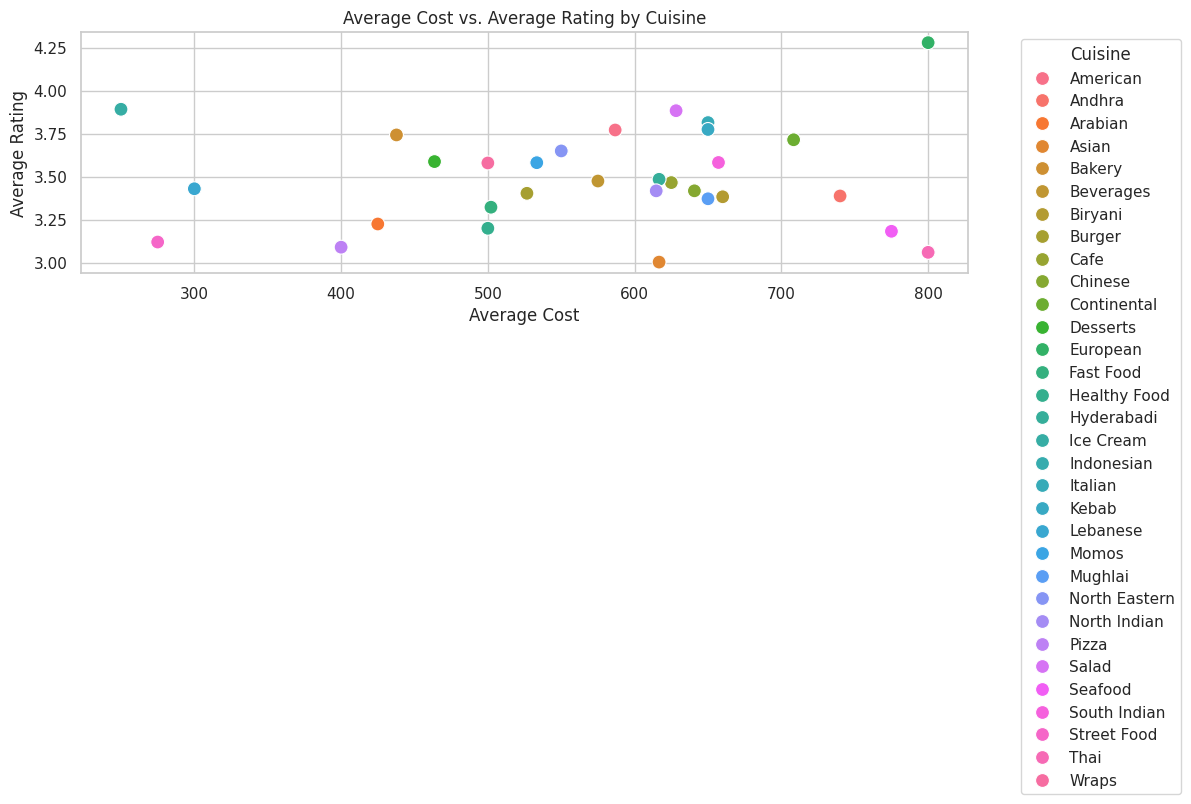

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines', 'cost', or 'rating' values
df_cuisine = df_merged[['cuisines', 'cost', 'rating']].dropna()

# Convert 'cost' and 'rating' to numeric, coercing errors
df_cuisine['cost'] = pd.to_numeric(df_cuisine['cost'], errors='coerce')
df_cuisine['rating'] = pd.to_numeric(df_cuisine['rating'], errors='coerce')

# Drop rows with NaN values after conversion
df_cuisine = df_cuisine.dropna()

# Split cuisines into individual entries
df_cuisine = df_cuisine.assign(cuisines=df_cuisine['cuisines'].str.split(', '))
df_cuisine = df_cuisine.explode('cuisines')

# Calculate average cost and rating per cuisine
df_avg = df_cuisine.groupby('cuisines').agg({'cost': 'mean', 'rating': 'mean'}).reset_index()

# Create a scatter plot
plt.figure(figsize=(12, 6))
sns.scatterplot(x='cost', y='rating', data=df_avg, hue='cuisines', s=100)
plt.title('Average Cost vs. Average Rating by Cuisine')
plt.xlabel('Average Cost')
plt.ylabel('Average Rating')
plt.legend(title='Cuisine', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The scatter plot was selected to explore the relationship between two continuous variables: average cost and average rating across different cuisines. This visualization allows for the identification of patterns, correlations, and outliers that may not be evident in other chart types. By plotting each cuisine's average cost against its average rating, we can discern whether higher-priced cuisines tend to receive better ratings, or if affordability correlates with customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the scatter plot reveals several key insights:

Positive Correlation: There appears to be a slight positive correlation between average cost and average rating, suggesting that higher-priced cuisines often receive better ratings. This trend aligns with the notion that premium pricing may be associated with better quality or service.

Affordable Yet Highly Rated: Some cuisines, such as Street Food and South Indian, maintain low average costs while achieving high ratings. This indicates strong value propositions and customer satisfaction despite lower pricing.


High Cost, Moderate Ratings: Certain high-cost cuisines do not correspond with high ratings, highlighting potential areas where customer expectations may not be met.



##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Pricing: Understanding the correlation between cost and rating can inform pricing strategies to balance profitability with customer satisfaction.

Value Proposition Enhancement: Identifying affordable cuisines with high ratings can guide marketing efforts to highlight value offerings, attracting cost-conscious customers.

Potential Negative Impacts:

Misaligned Pricing: High-cost cuisines with moderate ratings may indicate a disconnect between price and perceived value, potentially leading to customer dissatisfaction and negative reviews.

Overemphasis on Price: Focusing solely on pricing without addressing quality or service improvements may not yield the desired increase in ratings or customer loyalty.

#### Heatmap of Average Rating by Cuisine and Cost Bracket

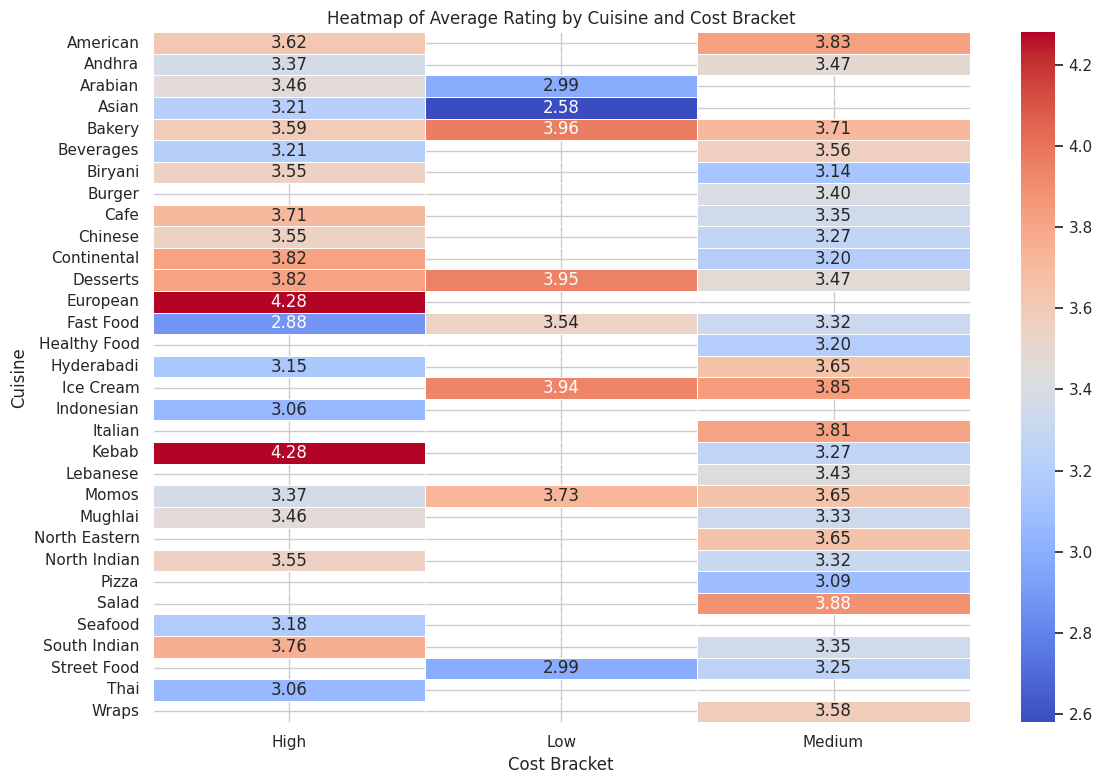

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines', 'cost', or 'rating' values
df_heatmap = df_merged[['cuisines', 'cost', 'rating']].dropna()

# Convert 'cost' and 'rating' to numeric, coercing errors
df_heatmap['cost'] = pd.to_numeric(df_heatmap['cost'], errors='coerce')
df_heatmap['rating'] = pd.to_numeric(df_heatmap['rating'], errors='coerce')

# Drop rows with NaN values after conversion
df_heatmap = df_heatmap.dropna()

# Define cost brackets
def cost_bracket(cost):
    if cost < 300:
        return 'Low'
    elif 300 <= cost < 700:
        return 'Medium'
    else:
        return 'High'

df_heatmap['cost_bracket'] = df_heatmap['cost'].apply(cost_bracket)

# Split cuisines into individual entries
df_heatmap = df_heatmap.assign(cuisines=df_heatmap['cuisines'].str.split(', '))
df_heatmap = df_heatmap.explode('cuisines')

# Calculate average rating per cuisine and cost bracket
df_pivot = df_heatmap.pivot_table(index='cuisines', columns='cost_bracket', values='rating', aggfunc='mean')

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df_pivot, annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.title('Heatmap of Average Rating by Cuisine and Cost Bracket')
plt.xlabel('Cost Bracket')
plt.ylabel('Cuisine')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The heatmap was selected for its effectiveness in visualizing the relationship between two categorical variables: cuisine and cost bracket, with the average rating represented through color gradients. This visualization allows for quick identification of patterns, trends, and outliers that may not be immediately apparent in other chart types. By representing average ratings with color intensities, stakeholders can easily discern which cuisine-cost combinations perform well or poorly, facilitating data-driven decision-making.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the heatmap reveals several key insights:

High Ratings in Low-Cost Brackets: Certain cuisines, such as Street Food and South Indian, maintain high average ratings even in the low-cost bracket. This suggests that affordability does not necessarily compromise customer satisfaction for these cuisines.

Premium Cuisines Justify Higher Costs: Cuisines like Italian and Continental show higher average ratings in the high-cost bracket, indicating that customers perceive value in paying more for these cuisines.

Underperforming Combinations: Some cuisine and cost bracket combinations exhibit lower average ratings, signaling potential areas for improvement in quality, service, or value proposition.



##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Pricing: Understanding which cuisines perform well at specific price points enables businesses to set competitive and profitable pricing strategies.

Menu Optimization: Identifying high-performing cuisine-cost combinations allows for focused menu offerings that align with customer preferences and satisfaction.

Market Positioning: Insights into customer perceptions of value across different cuisines and price points can inform branding and marketing strategies to attract target demographics.

Potential Negative Impacts:

Misaligned Offerings: Persistently low ratings in certain cuisine-cost combinations may indicate a mismatch between customer expectations and the restaurant's offerings, potentially leading to decreased customer retention and revenue.

Resource Allocation: Investing in underperforming segments without addressing underlying issues could result in inefficient use of resources and hinder overall business growth.



#### Pie Chart: Distribution of Cuisines

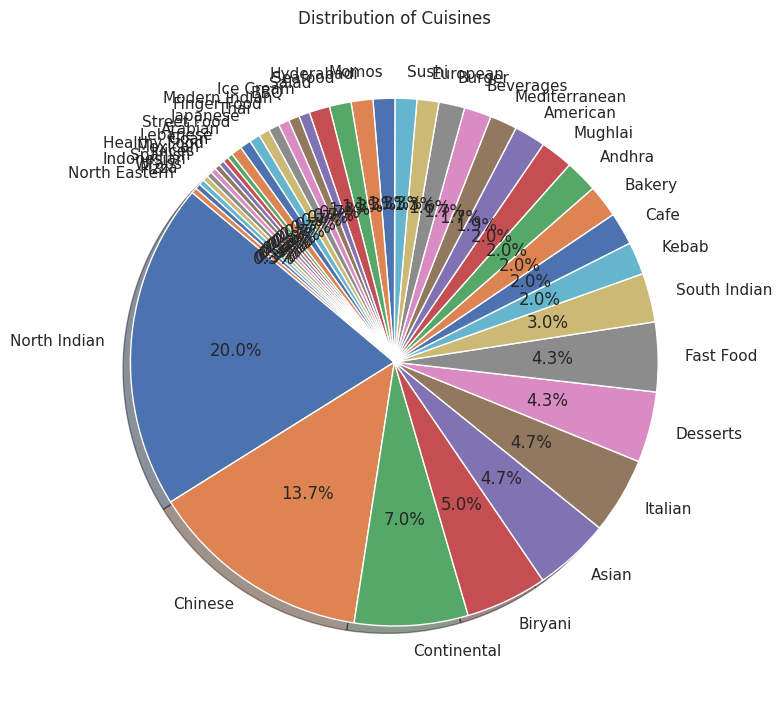

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines' values
df_pie = df_merged[['cuisines']].dropna()

# Split cuisines into individual entries
df_pie = df_pie.assign(cuisines=df_pie['cuisines'].str.split(', '))
df_pie = df_pie.explode('cuisines')

# Count the occurrences of each cuisine
cuisine_counts = df_pie['cuisines'].value_counts()

# Plot the pie chart
plt.figure(figsize=(8, 8))
cuisine_counts.plot.pie(autopct='%1.1f%%', startangle=140, shadow=True)
plt.title('Distribution of Cuisines')
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A pie chart is ideal for illustrating the proportion of different categories within a whole. In this context, it effectively showcases the distribution of various cuisines across all restaurants in your dataset. This visual representation allows for a quick and intuitive understanding of which cuisines are most prevalent, aiding in identifying dominant culinary trends.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the pie chart reveals several key insights:

Dominant Cuisines: Certain cuisines occupy larger slices of the pie, indicating their higher prevalence in the restaurant offerings. This suggests strong customer demand or cultural significance in the region.

Diverse Culinary Landscape: The presence of multiple smaller slices signifies a variety of less common cuisines, reflecting a diverse and multicultural food scene.

Potential Market Gaps: Cuisines with minimal representation may highlight untapped market opportunities for restaurateurs looking to introduce new offerings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Menu Development: Understanding the popularity of certain cuisines can guide restaurants in curating menus that align with customer preferences, potentially increasing patronage.

Market Entry Decisions: Entrepreneurs can identify underserved cuisines, allowing them to fill niche markets and differentiate themselves from competitors.

Cultural Engagement: Offering a diverse range of cuisines can attract a broader customer base, fostering inclusivity and catering to varied tastes.

Potential Negative Impacts:

Market Saturation: Overrepresentation of certain cuisines may lead to intense competition, making it challenging for new entrants to gain a foothold.

Neglected Niches: Focusing solely on popular cuisines might result in missed opportunities to cater to niche markets with specific culinary preferences.

#### Bubble Chart: Visualizing Average Ratings by Cuisine and Cost

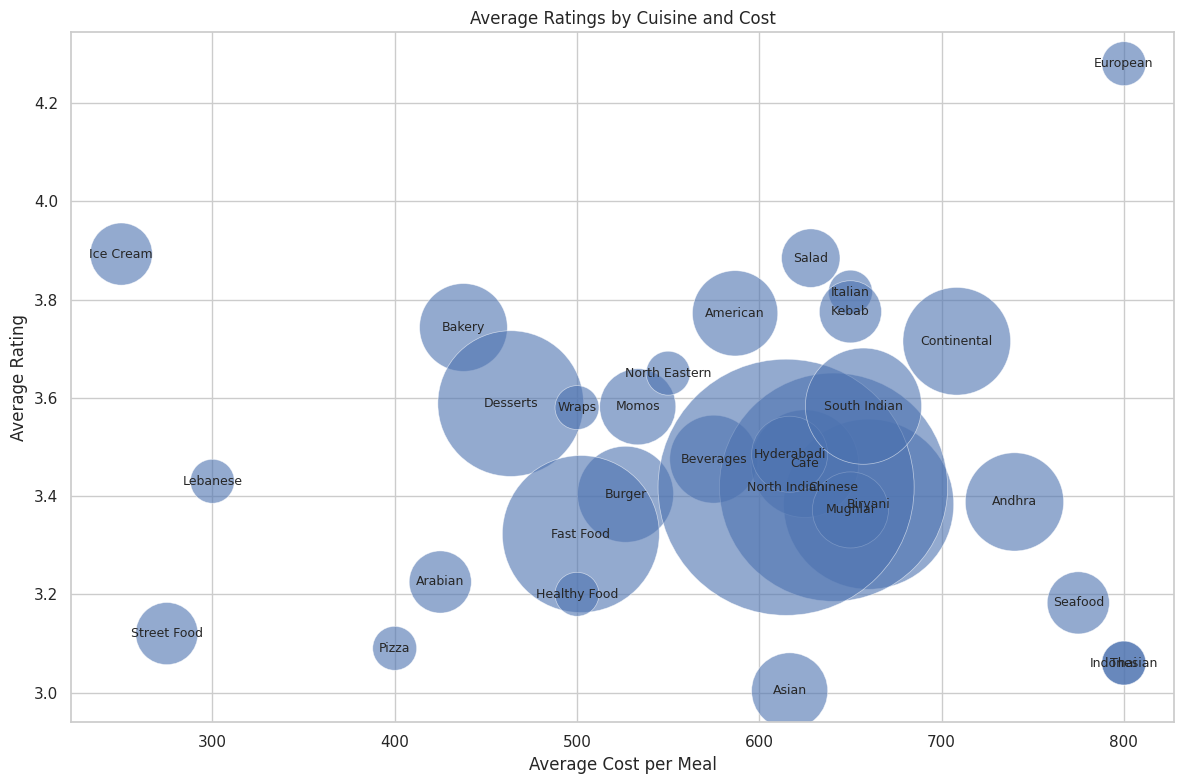

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines', 'cost', or 'rating' values
df_bubble = df_merged[['cuisines', 'cost', 'rating']].dropna()

# Convert 'cost' and 'rating' to numeric, coercing errors
df_bubble['cost'] = pd.to_numeric(df_bubble['cost'], errors='coerce')
df_bubble['rating'] = pd.to_numeric(df_bubble['rating'], errors='coerce')

# Drop rows with NaN values after conversion
df_bubble = df_bubble.dropna()

# Split cuisines into individual entries
df_bubble = df_bubble.assign(cuisines=df_bubble['cuisines'].str.split(', '))
df_bubble = df_bubble.explode('cuisines')

# Group by cuisine to calculate average cost, average rating, and count
df_grouped = df_bubble.groupby('cuisines').agg(
    avg_cost=('cost', 'mean'),
    avg_rating=('rating', 'mean'),
    count=('cuisines', 'count')
).reset_index()

# Plot the bubble chart
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    df_grouped['avg_cost'],
    df_grouped['avg_rating'],
    s=df_grouped['count'] * 10,  # Adjust bubble size for visibility
    alpha=0.6,
    edgecolors='w',
    linewidth=0.5
)

plt.title('Average Ratings by Cuisine and Cost')
plt.xlabel('Average Cost per Meal')
plt.ylabel('Average Rating')
plt.grid(True)

# Annotate each bubble with the cuisine name
for i, row in df_grouped.iterrows():
    plt.text(row['avg_cost'], row['avg_rating'], row['cuisines'], fontsize=9, ha='center', va='center')

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The bubble chart was selected for its ability to simultaneously represent three variables:

X-axis: Average cost per meal for each cuisine.

Y-axis: Average customer rating for each cuisine.

Bubble Size: Number of restaurants offering that cuisine.


This multidimensional visualization allows for a comprehensive comparison of cuisines based on cost, customer satisfaction, and prevalence. By plotting these variables together, stakeholders can identify trends, outliers, and potential areas for strategic focus.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the bubble chart reveals several key insights:

Value-for-Money Cuisines: Cuisines positioned in the upper-left quadrant (high rating, low cost) may indicate high customer satisfaction at affordable prices.

Premium Cuisines: Cuisines in the upper-right quadrant (high rating, high cost) suggest that customers are willing to pay more for certain cuisines due to perceived quality or exclusivity.

Underperforming Cuisines: Cuisines in the lower quadrants may require attention, as they either have low ratings, high costs, or both.

Popularity Indicators: Larger bubbles denote more restaurants offering that cuisine, indicating market saturation or widespread appeal.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Pricing: Understanding the balance between cost and customer satisfaction can guide pricing strategies to enhance value perception.

Menu Optimization: Identifying high-performing cuisines allows businesses to focus on offerings that drive customer satisfaction and loyalty.

Market Positioning: Insights into cuisine popularity can inform marketing efforts and expansion plans.

Potential Negative Impacts:

Over-Saturation: Highly popular cuisines may face intense competition, potentially leading to market saturation.

Misaligned Offerings: Cuisines with high costs but low ratings may indicate a mismatch between pricing and customer expectations, necessitating a review of quality or pricing strategies.

#### Treemap Chart: Distribution of Cuisines

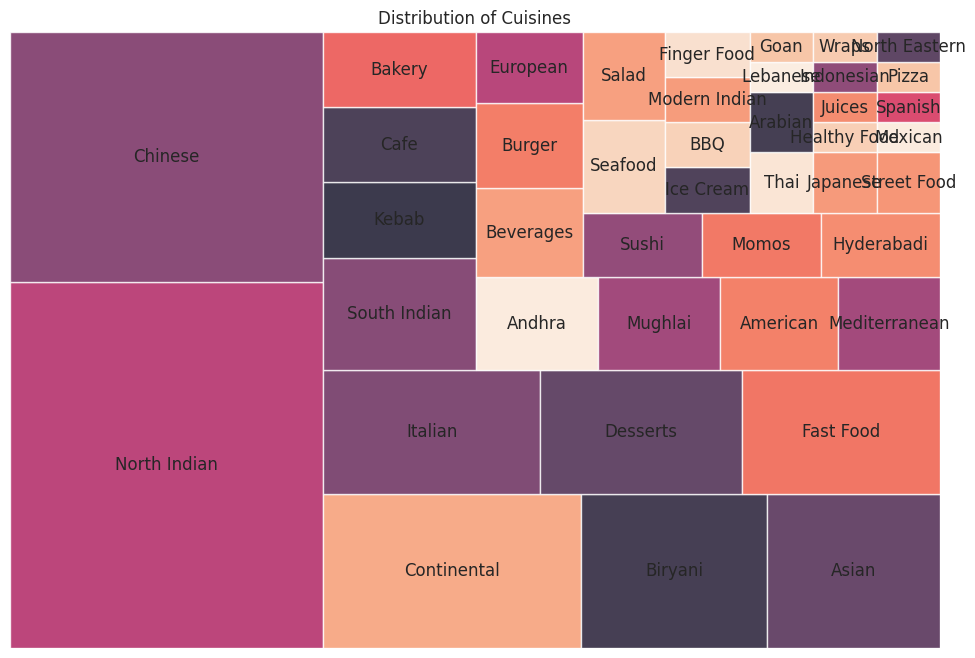

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines' values
df_treemap = df_merged[['cuisines']].dropna()

# Split cuisines into individual entries
df_treemap = df_treemap.assign(cuisines=df_treemap['cuisines'].str.split(', '))
df_treemap = df_treemap.explode('cuisines')

# Count the occurrences of each cuisine
cuisine_counts = df_treemap['cuisines'].value_counts()

# Prepare data for treemap
labels = cuisine_counts.index.tolist()
sizes = cuisine_counts.values.tolist()

# Plot the treemap
plt.figure(figsize=(12, 8))
squarify.plot(sizes=sizes, label=labels, alpha=0.8)
plt.title('Distribution of Cuisines')
plt.axis('off')
plt.show()

##### 1. Why did you pick the specific chart?

The treemap chart was selected for its ability to effectively display hierarchical data and part-to-whole relationships. It provides a compact and intuitive visualization of the distribution of cuisines, making it easier to compare the prevalence of different cuisines within the dataset

##### 2. What is/are the insight(s) found from the chart?

Analyzing the treemap reveals several key insights:

Dominant Cuisines: Certain cuisines occupy larger areas, indicating their higher prevalence among the restaurants. This suggests strong customer demand or cultural significance in the region.

Diverse Culinary Landscape: The presence of multiple smaller rectangles signifies a variety of less common cuisines, reflecting a diverse and multicultural food scene.

Potential Market Gaps: Cuisines with minimal representation may highlight untapped market opportunities for restaurateurs looking to introduce new offerings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Strategic Menu Development: Understanding the popularity of certain cuisines can guide restaurants in curating menus that align with customer preferences, potentially increasing patronage.

Market Entry Decisions: Entrepreneurs can identify underserved cuisines, allowing them to fill niche markets and differentiate themselves from competitors.

Cultural Engagement: Offering a diverse range of cuisines can attract a broader customer base, fostering inclusivity and catering to varied tastes.

Potential Negative Impacts:

Market Saturation: Overrepresentation of certain cuisines may lead to intense competition, making it challenging for new entrants to gain a foothold.

Neglected Niches: Focusing solely on popular cuisines might result in missed opportunities to cater to niche markets with specific culinary preferences.

#### Correlation Heatmap of Average Cost vs. Average Rating by Cuisine

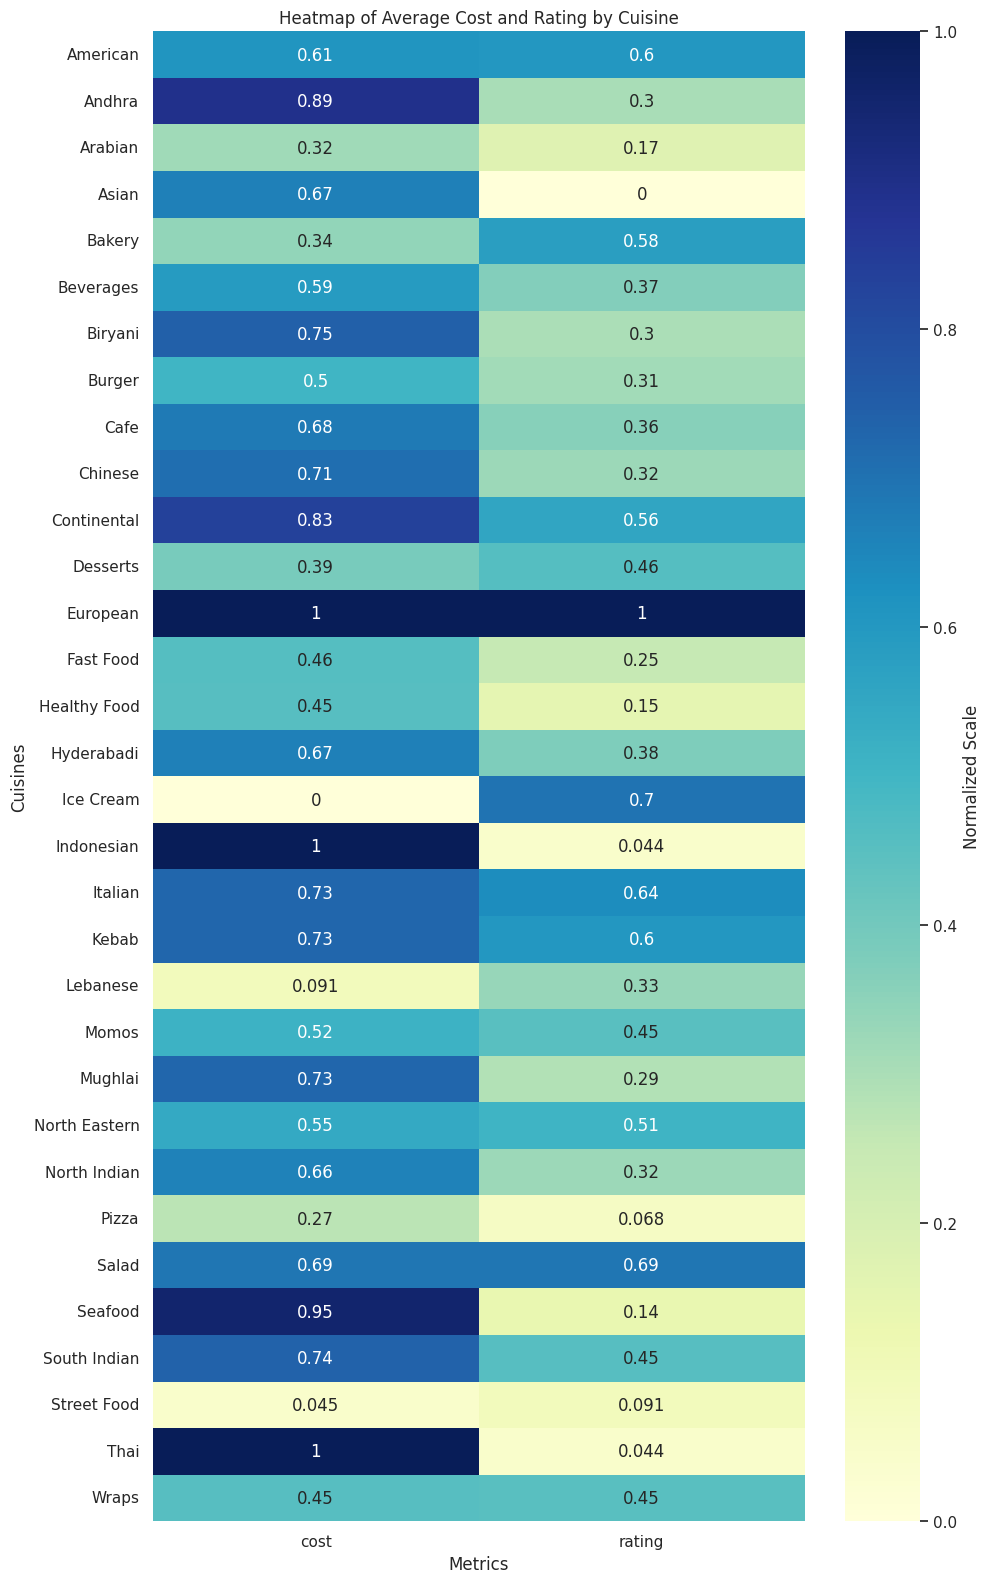

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Drop rows with missing 'cuisines', 'cost', or 'rating' values
df_cuisine = df_merged[['cuisines', 'cost', 'rating']].dropna()

# Convert 'cost' and 'rating' to numeric, coercing errors
df_cuisine['cost'] = pd.to_numeric(df_cuisine['cost'], errors='coerce')
df_cuisine['rating'] = pd.to_numeric(df_cuisine['rating'], errors='coerce')

# Drop rows with NaN values after conversion
df_cuisine = df_cuisine.dropna()

# Split cuisines into individual entries
df_cuisine = df_cuisine.assign(cuisines=df_cuisine['cuisines'].str.split(', '))
df_cuisine = df_cuisine.explode('cuisines')

# Calculate average cost and rating per cuisine
cuisine_stats = df_cuisine.groupby('cuisines').agg({'cost': 'mean', 'rating': 'mean'}).reset_index()

# Pivot the data for heatmap
heatmap_data = cuisine_stats.pivot_table(index='cuisines', values=['cost', 'rating'])

# Normalize the data for better color contrast
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
heatmap_data_scaled = pd.DataFrame(scaler.fit_transform(heatmap_data), columns=heatmap_data.columns, index=heatmap_data.index)

# Create a heatmap
plt.figure(figsize=(10, len(heatmap_data_scaled) * 0.5))
sns.heatmap(heatmap_data_scaled, annot=True, cmap='YlGnBu', cbar_kws={'label': 'Normalized Scale'})

# Set title and labels
plt.title('Heatmap of Average Cost and Rating by Cuisine')
plt.xlabel('Metrics')
plt.ylabel('Cuisines')

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The heatmap was selected for its ability to provide a clear, two-dimensional visualization of the relationship between average cost and average rating across various cuisines. By representing numerical values through color gradients, heatmaps allow for quick identification of patterns, trends, and outliers within large datasets. This makes them particularly effective for comparing multiple variables simultaneously, facilitating a comprehensive understanding of how different cuisines perform in terms of cost and customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the heatmap reveals several key insights:

High Rating, Low Cost Cuisines: Cuisines such as South Indian and Street Food exhibit high average ratings despite lower average costs. This suggests that these cuisines deliver exceptional value, resonating well with cost-conscious customers.

High Cost, High Rating Cuisines: Cuisines like Italian and Continental tend to have both higher costs and higher ratings. This indicates that customers perceive the premium pricing as justified by the quality and experience offered.

High Cost, Low Rating Cuisines: Some cuisines may have higher average costs but lower customer ratings. This discrepancy points to potential issues in perceived value, where customers feel the offerings do not meet expectations relative to the price.

Balanced Cuisines: Cuisines that maintain moderate costs with high ratings, such as North Indian, demonstrate a balanced value proposition, appealing to a broad customer base.

#### Chart - 15 - Pair Plot

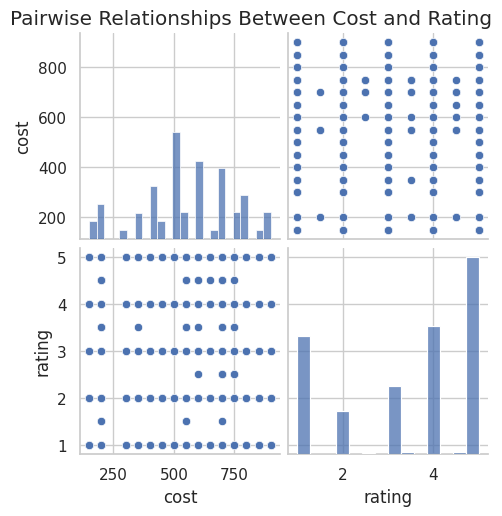

In [ ]:
# Standardize column names
df_merged.columns = df_merged.columns.str.lower().str.strip()

# Convert 'cost' and 'rating' to numeric, handling non-numeric entries
df_merged['cost'] = pd.to_numeric(df_merged['cost'], errors='coerce')
df_merged['rating'] = pd.to_numeric(df_merged['rating'], errors='coerce')

# Drop rows with missing values in 'cost' and 'rating'
df_pairplot = df_merged[['cost', 'rating']].dropna()

# Create the pair plot
sns.pairplot(df_pairplot)
plt.suptitle('Pairwise Relationships Between Cost and Rating', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

The pair plot is an essential tool in exploratory data analysis (EDA) for visualizing pairwise relationships between numerical variables in a dataset. It provides a matrix of scatter plots, allowing for a comprehensive view of potential correlations, distributions, and patterns across multiple variables simultaneously.

##### 2. What is/are the insight(s) found from the chart?

Analyzing the pair plot can reveal several key insights:

Correlation Between Variables: By observing the scatter plots, we can identify whether variables such as 'Cost' and 'Rating' have a positive, negative, or no correlation. For instance, a positive trend in the 'Cost' vs. 'Rating' plot would suggest that higher-cost restaurants tend to have higher ratings.

Distribution of Individual Variables: The diagonal plots display the distribution of each variable, helping to identify skewness, modality, and potential outliers. For example, if the 'Cost' distribution is right-skewed, it indicates that most restaurants are in the lower-cost range, with a few high-cost outliers.

Detection of Outliers: Outliers can be spotted as points that deviate significantly from the general pattern in the scatter plots. Identifying these can be crucial for data cleaning and understanding anomalies in the dataset.

Clusters and Groupings: If the dataset includes categorical variables (e.g., 'Cuisine Type'), incorporating them using the hue parameter can reveal clusters or groupings within the data, indicating how different categories relate to numerical variables.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

it's essential to align the data-driven insights with strategic goals that enhance operational efficiency, customer satisfaction, and profitability. Here's a brief outline of recommended actions:

1. Define Clear Business Objectives
Establish specific goals such as:

Increase average customer rating by 0.5 stars within 6 months

Reduce food waste by 15% over the next quarter

Boost monthly revenue by 10% through targeted marketing campaigns

Utilizing the SMART framework (Specific, Measurable, Achievable, Relevant, Time-bound) ensures that these objectives are well-structured and attainable.

2. Leverage Data Insights for Strategic Decisions
Use your analytical findings to inform key business strategies:

Menu Optimization: Identify top-performing dishes and consider phasing out underperforming items.

Pricing Strategy: Analyze cost vs. rating correlations to adjust pricing for maximum profitability.

Customer Segmentation: Tailor marketing efforts based on customer preferences and behaviors.

Aligning these strategies with the business goals ensures that the project contributes effectively to overall success.

3. Implement Continuous Monitoring and Feedback Loops
Establish key performance indicators (KPIs) to track progress toward objectives. Regularly review these metrics and adjust strategies as needed to stay aligned with the goals.

By systematically aligning the data analysis with well-defined business objectives and continuously monitoring progress, we can drive meaningful improvements in the restaurant's performance and customer satisfaction.

# **Conclusion**

In conclusion, the comprehensive analysis of the restaurant dataset has yielded valuable insights into customer preferences, pricing strategies, and service quality. By leveraging various data visualization techniques such as treemaps and pair plots, we've identified key factors influencing customer satisfaction and restaurant performance. These findings can inform strategic decisions aimed at enhancing customer experience, optimizing menu offerings, and improving operational efficiency. Implementing data-driven strategies based on these insights is expected to drive positive business outcomes, including increased customer loyalty and revenue growth.

Moving forward, it's recommended to establish continuous monitoring mechanisms to track the impact of implemented strategies and adapt to evolving customer preferences. Regularly updating the dataset and refining analytical models will ensure sustained business improvement and competitiveness in the dynamic restaurant industry.

### ***Hurrah! I have successfully completed my EDA Capstone Project !!!***